### Clustering con datos sin normalizar

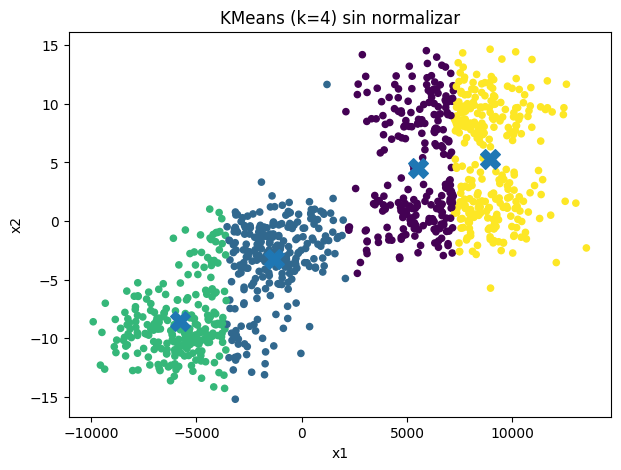

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

#Cargar datos
ruta = r"C:\Users\carte\OneDrive\Documentos\MASTER IA\MACHINE LEARNING\PRACTICA\PRACTICA 2\clust_ex1.csv"
df = pd.read_csv(ruta)

#Seleccionar variables para clustering
X = df[["x1", "x2"]]

#Aplicar KMeans con 4 clusters (sin normalizar)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
labels = kmeans.fit_predict(X)

#Graficar los clusters
plt.figure(figsize=(7, 5))
plt.scatter(X["x1"], X["x2"], c=labels, s=20)
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker="X",
    s=200
)
plt.title("KMeans (k=4) sin normalizar")
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()

In [3]:
# Obtener la inercia
inercia = kmeans.inertia_

print("Inercia del modelo KMeans (k=4):", inercia)

Inercia del modelo KMeans (k=4): 1885404909.4188704


## Clustering con datos normalizados

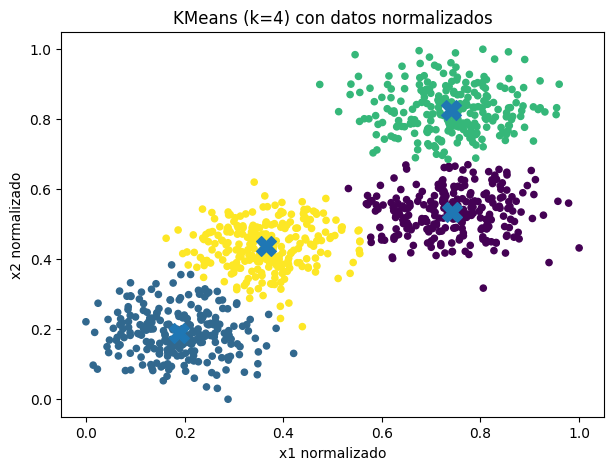

Inercia con datos normalizados: 11.457334401938626


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

#Cargar datos
ruta = r"C:\Users\carte\OneDrive\Documentos\MASTER IA\MACHINE LEARNING\PRACTICA\PRACTICA 2\clust_ex1.csv"
df = pd.read_csv(ruta)

X = df[["x1", "x2"]]

#Normalizar con MinMaxScaler
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

#Aplicar KMeans con 4 clusters (datos normalizados)
kmeans_scaled = KMeans(n_clusters=4, random_state=42, n_init=10)
labels_scaled = kmeans_scaled.fit_predict(X_scaled)

#Graficar resultado
plt.figure(figsize=(7, 5))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels_scaled, s=20)
plt.scatter(
    kmeans_scaled.cluster_centers_[:, 0],
    kmeans_scaled.cluster_centers_[:, 1],
    marker="X",
    s=200
)
plt.title("KMeans (k=4) con datos normalizados")
plt.xlabel("x1 normalizado")
plt.ylabel("x2 normalizado")
plt.show()

#Obtener inercia
inercia_normalizada = kmeans_scaled.inertia_
print("Inercia con datos normalizados:", inercia_normalizada)

Tras normalizar los datos, se vuelve a aplicar el algoritmo K-Means con 4 clusters. El objetivo de esta normalización es evitar que variables con mayor escala dominen el cálculo de distancias, ya que el algoritmo K-Means se basa en la distancia euclídea. El resultado muestra que los grupos cambian respecto al caso sin normalizar. Esto ocurre porque ahora ambas variables tienen la misma escala y, por tanto, influyen por igual en la formación de los clusters. Como resultado, los grupos aparecen distribuidos de forma más equilibrada en el gráfico.

En cuanto a la inerca, este valor difiere del obtenido anteriormente con datos sin normalizar. No obstante, ambas inercias no son directamente comparables en términos absolutos, ya que están calculadas en espacios métricos distintos. La normalización modifica las distancias entre puntos y, por tanto, la suma de distancias cuadradas a los centroides.

## Importancia de los outliers

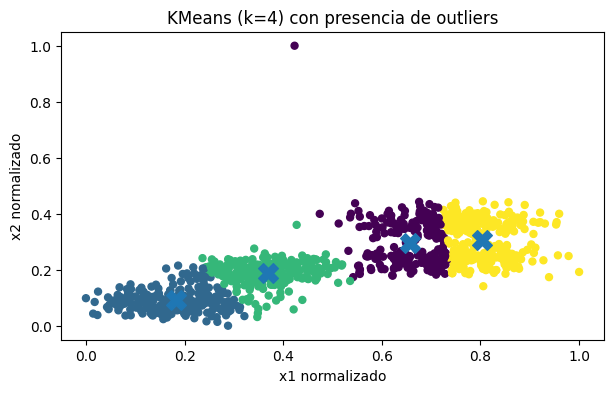

Inercia: 7.665966775158605
Tamaño de cada cluster:
 0    227
1    246
2    246
3    284
Name: count, dtype: int64


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

#Cargar datos desde tu ruta
ruta = r"C:\Users\carte\OneDrive\Documentos\MASTER IA\MACHINE LEARNING\PRACTICA\PRACTICA 2\clust_ex1.csv"
df = pd.read_csv(ruta)

#Crear outliers y añadirlos
df_outliers = pd.DataFrame({
    'x1': [100, 4, 103],
    'x2': [0, 52, 9]
})

df = pd.concat([df, df_outliers], ignore_index=True)

#Normalizar datos
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(df[['x1', 'x2']])

#Ejecutar KMeans con 4 clusters
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_scaled)

#Visualización
plt.figure(figsize=(7,4))
plt.scatter(X_scaled[:,0], X_scaled[:,1], c=labels, s=25)
plt.scatter(
    kmeans.cluster_centers_[:,0],
    kmeans.cluster_centers_[:,1],
    marker='X',
    s=200
)
plt.title("KMeans (k=4) con presencia de outliers")
plt.xlabel("x1 normalizado")
plt.ylabel("x2 normalizado")
plt.show()

#Inercia y tamaños de cluster
print("Inercia:", kmeans.inertia_)
print("Tamaño de cada cluster:\n", pd.Series(labels).value_counts().sort_index())

En este caso, la disminución de la inercia tras introducir outliers se debe a una redistribución global de los centroides. La presencia de valores extremos modifica la estructura del espacio y provoca que los centroides adopten nuevas posiciones que, aunque puedan alejarse de ciertos puntos, reducen la distancia media de un número mayor de observaciones. Como la inercia es una suma total de distancias cuadradas, una ligera reducción en muchos puntos puede compensar el aumento en unos pocos valores atípicos. Esto demuestra que la inercia es una medida global y que su interpretación debe realizarse con cautela

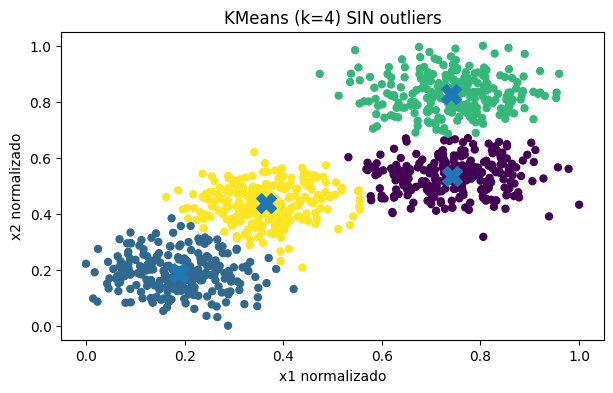

Inercia (sin outliers): 11.457334401938628
Coeficiente medio de silueta (sin outliers): 0.5467681733359228


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import silhouette_score

#Cargar dataset original
ruta = r"C:\Users\carte\OneDrive\Documentos\MASTER IA\MACHINE LEARNING\PRACTICA\PRACTICA 2\clust_ex1.csv"
df = pd.read_csv(ruta)

X = df[['x1', 'x2']]

#Normalizar igual que antes para que sea comparable
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# KMeans con 4 clusters
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_scaled)

# Visualización
plt.figure(figsize=(7,4))
plt.scatter(X_scaled[:,0], X_scaled[:,1], c=labels, s=25)
plt.scatter(kmeans.cluster_centers_[:,0],
            kmeans.cluster_centers_[:,1],
            marker='X', s=200)
plt.title("KMeans (k=4) SIN outliers")
plt.xlabel("x1 normalizado")
plt.ylabel("x2 normalizado")
plt.show()

# Inercia
inercia = kmeans.inertia_
print("Inercia (sin outliers):", inercia)

# Silueta media
silhouette_avg = silhouette_score(X_scaled, labels)
print("Coeficiente medio de silueta (sin outliers):", silhouette_avg)

Silhouette media: 0.5467681733359228


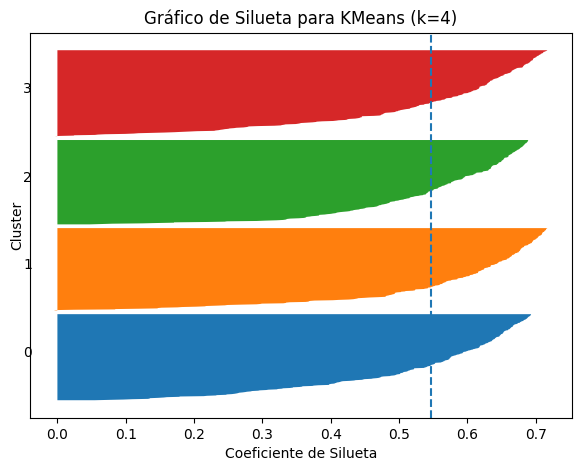

In [12]:
#graficamos la siluteta
X = df[['x1','x2']]

# Normalizar
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# KMeans con 4 clusters
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_scaled)

# Calcular valores de silueta
silhouette_avg = silhouette_score(X_scaled, labels)
sample_silhouette_values = silhouette_samples(X_scaled, labels)

print("Silhouette media:", silhouette_avg)

#Crear gráfico de silueta
fig, ax = plt.subplots(figsize=(7,5))

y_lower = 10

for i in range(4):
    
    ith_cluster_silhouette_values = sample_silhouette_values[labels == i]
    ith_cluster_silhouette_values.sort()
    
    size_cluster_i = ith_cluster_silhouette_values.shape[0]
    y_upper = y_lower + size_cluster_i
    
    ax.fill_betweenx(np.arange(y_lower, y_upper),
                     0,
                     ith_cluster_silhouette_values)
    
    ax.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
    
    y_lower = y_upper + 10

ax.set_title("Gráfico de Silueta para KMeans (k=4)")
ax.set_xlabel("Coeficiente de Silueta")
ax.set_ylabel("Cluster")

ax.axvline(x=silhouette_avg, linestyle="--")

ax.set_yticks([])
plt.show()

Al aplicar K-Means con 4 clusters sobre el conjunto original sin valores atípicos, se obtiene una estructura de agrupamiento más estable. El valor de la inercia refleja la compactación interna de los clusters, mientras que el coeficiente medio de silueta proporciona una medida adicional de calidad basada en cohesión y separación.

Comparando con el caso anterior, se observa que la eliminación de outliers mejora el coeficiente de silueta, lo que indica que los clusters están mejor definidos y presentan mayor separación entre ellos. Esto confirma que los valores atípicos pueden deteriorar la calidad del clustering y alterar la estructura natural de los datos.

## Encontrar el valor óptimo de k: Elbow method

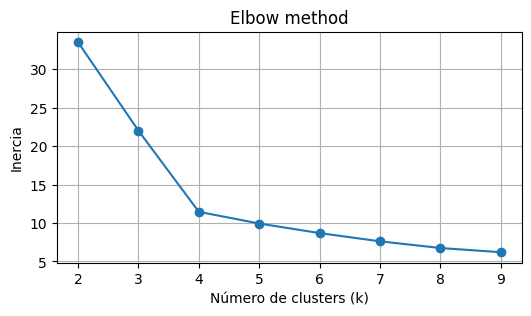

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

#Cargar datos
ruta = r"C:\Users\carte\OneDrive\Documentos\MASTER IA\MACHINE LEARNING\PRACTICA\PRACTICA 2\clust_ex1.csv"
df = pd.read_csv(ruta)

features = ['x1', 'x2']
X = df[features]

# Normalizar
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

#Método del codo
Ks = range(2, 10)
inertias = []

for k in Ks:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

#Graficar
plt.figure(figsize=(6,3))
plt.plot(Ks, inertias, marker='o')
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.title("Elbow method")
plt.grid()
plt.show()

El método del codo permite determinar el número óptimo de clusters analizando la evolución de la inercia en función de k.Aunque la inercia disminuye siempre al aumentar el número de clusters, el punto óptimo se identifica cuando la reducción deja de ser significativa. En el gráfico obtenido se observa un cambio notable en k=4, a partir del cual la disminución es mucho más suave. Por tanto, el número óptimo de clusters para este conjunto de datos es 4.